## Import

In [1]:
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
import os
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
CUDA available: False


/home/jkitzmann/.local/lib/python3.11/site-packages/torch/cuda/__init__.py:241: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [7]:
!nvidia-smi

Sun Nov 15 15:03:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.163.01             Driver Version: 550.163.01     CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A10                     Off |   00000000:A5:00.0 Off |                    0 |
|  0%   26C    P8             17W /  150W |       1MiB /  23028MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from pathlib import Path
import kagglehub

data_dir = Path("./Data")

if not data_dir.exists() or not any(data_dir.iterdir()):
    path = kagglehub.dataset_download(
        "jadhavrajveer/medical-decathlon-lung-tumor-segmentation",
        output_dir=str(data_dir)
    )
    print("Dataset downloaded to:", path)
    ! mv /home/jkitzmann/.cache/kagglehub/datasets/jadhavrajveer/medical-decathlon-lung-tumor-segmentation/versions/1 ./Data
else:
    print("Dataset already exists in:", data_dir.resolve())

Dataset already exists in: /home/jkitzmann/dlmi/SlicerLab/Data


/home/jkitzmann/.local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Change the /home... to the path above

mv: cannot stat '/home/jkitzmann/.cache/kagglehub/datasets/jadhavrajveer/medical-decathlon-lung-tumor-segmentation/versions/1': No such file or directory


## Preprocessing functions

In [4]:
def resample_isotropic(image, spacing=1.0,
                       interpolator=sitk.sitkLinear):

    original_spacing = image.GetSpacing()
    original_size = image.GetSize()

    new_spacing = [spacing] * 3

    new_size = [
        int(round(original_spacing[i] * original_size[i] / spacing))
        for i in range(3)
    ]

    resampler = sitk.ResampleImageFilter()
    resampler.SetOutputSpacing(new_spacing)
    resampler.SetSize(new_size)
    resampler.SetOutputDirection(image.GetDirection())
    resampler.SetOutputOrigin(image.GetOrigin())
    resampler.SetInterpolator(interpolator)
    resampler.SetDefaultPixelValue(-1000)

    return resampler.Execute(image)

## Visualize training data

In [5]:
def show(image, segmentation=None, dims=None):

    im = sitk.GetArrayViewFromImage(image)

    if segmentation is not None:
        seg = sitk.GetArrayViewFromImage(segmentation)

    if dims is None:
        dims = [x // 2 for x in im.shape]

    fig, axes = plt.subplots(1, 3, figsize=(15, 10))

    slices = [
        (im[dims[0]], seg[dims[0]] if segmentation is not None else None, 'Axial'),
        (im[:, dims[1], :], seg[:, dims[1], :] if segmentation is not None else None, 'Coronal'),
        (im[:, :, dims[2]], seg[:, :, dims[2]] if segmentation is not None else None, 'Sagittal')
    ]

    for ax, (img_slice, seg_slice, title) in zip(axes, slices):
        ax.imshow(img_slice, cmap='gray')

        if seg_slice is not None:
            ax.imshow(
                np.ma.masked_where(seg_slice == 0, seg_slice),
                cmap='autumn',
                alpha=0.5
            )

        ax.set_title(title)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

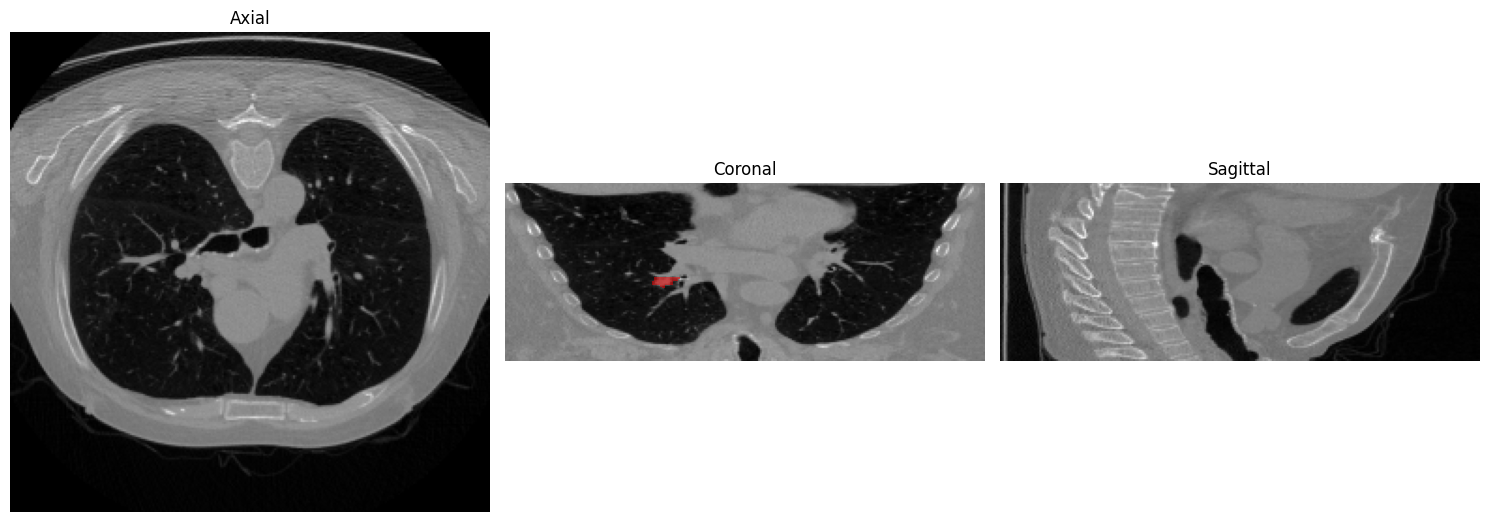

image spacing:  (1.0, 1.0, 1.0)
mask spacing:  (1.0, 1.0, 1.0)


In [6]:
data_path = r'Data/Lung-Tumor-Segmentation'
num = 11

test_image = resample_isotropic(
    sitk.ReadImage(os.path.join(data_path, f'{num}/data/{num}_data.nii'))
)
test_seg = resample_isotropic(
    sitk.ReadImage(os.path.join(data_path, f'{num}/label/{num}_mask.nii')),
    interpolator = sitk.sitkNearestNeighbor
)

show(test_image, test_seg)
print('image spacing: ', test_image.GetSpacing())
print('mask spacing: ',test_seg.GetSpacing())

## Dataset and Dataloader